# Módulo 1 — Exploración de datos de precios

**Proyecto:** Market Intelligence Copilot — Pipeline NLP de Volatilidad

Sanity checks visuales sobre `data/processed/prices_daily.parquet` (WTI, Brent, Henry Hub).
El objetivo es confirmar que las series son coherentes, entender la naturaleza de los
log-retornos (colas gordas) y revisar los NaN **antes** de pasar a los módulos de modelado.

> Los datos ya pasaron los tests Point-in-Time (`tests/test_pit_integrity.py`).
> Acá hacemos la inspección visual, no la validación formal.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

# Localizar la raíz del proyecto (donde vive src/) para poder importar config.
_root = Path.cwd()
while not (_root / "src").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
from src import config

# Estilo limpio y consistente para todos los gráficos.
plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

ASSETS = ["WTI", "BRENT", "HENRY_HUB"]
COLORS = {"WTI": "#1f77b4", "BRENT": "#d62728", "HENRY_HUB": "#2ca02c"}
print("Raíz del proyecto:", _root)

Raíz del proyecto: C:\Users\Juancho\market-intel-copilot


## 1. Carga de datos

Levantamos el dataset procesado (formato largo) y lo pasamos también a formato
ancho (`fecha × activo`) para graficar y calcular cómodo.

In [2]:
df = pd.read_parquet(config.PRICES_DAILY_PARQUET)
print("Filas:", len(df), "| Activos:", list(df["asset"].cat.categories))
print("Rango de fechas:", df["date"].min().date(), "->", df["date"].max().date())
df.head()

Filas: 9633 | Activos: ['WTI', 'BRENT', 'HENRY_HUB']
Rango de fechas: 2014-01-02 -> 2026-06-22


,date,asset,close,log_return,source
0,2014-01-02 00:00:00+00:00,WTI,95.14,-0.031351,EIA
1,2014-01-03 00:00:00+00:00,WTI,93.66,-0.015678,EIA
2,2014-01-06 00:00:00+00:00,WTI,93.12,-0.005782,EIA
3,2014-01-07 00:00:00+00:00,WTI,93.31,0.002038,EIA
4,2014-01-08 00:00:00+00:00,WTI,91.90,-0.015226,EIA


In [3]:
# Formato ancho: una columna por activo. Útil para graficar y estadística.
close = df.pivot(index="date", columns="asset", values="close").reindex(columns=ASSETS)
ret = df.pivot(index="date", columns="asset", values="log_return").reindex(columns=ASSETS)
close.tail()

asset,WTI,BRENT,HENRY_HUB
date,,,
2026-06-16 00:00:00+00:00,79.80,80.50,3.10
2026-06-17 00:00:00+00:00,80.65,80.33,3.25
2026-06-18 00:00:00+00:00,80.35,79.35,3.08
2026-06-19 00:00:00+00:00,NaN,80.46,NaN
2026-06-22 00:00:00+00:00,78.94,76.49,3.16


## 2. Series de precios

Un panel por activo: las unidades difieren (WTI y Brent en USD/barril, Henry Hub
en USD/MMBTU), por eso **no** comparten eje vertical.

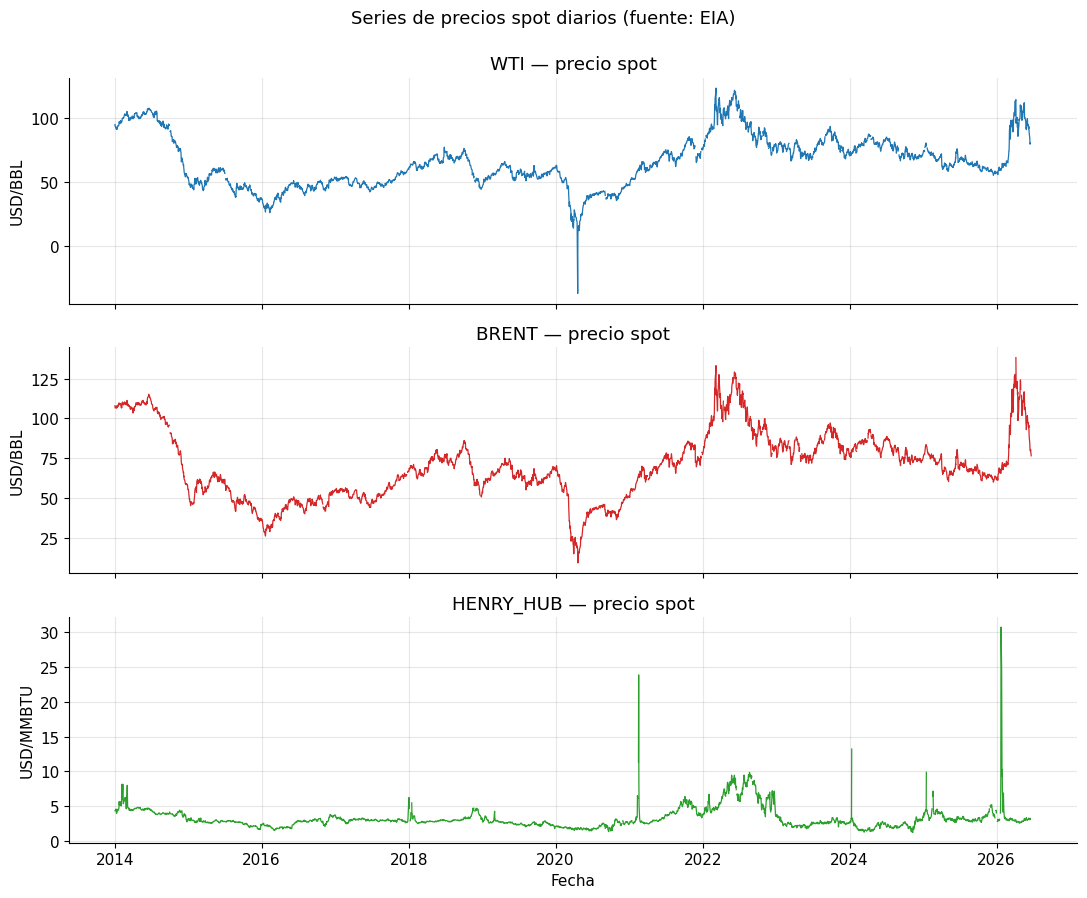

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, asset in zip(axes, ASSETS):
    ax.plot(close.index, close[asset], color=COLORS[asset], lw=0.9)
    ax.set_title(f"{asset} — precio spot")
    ax.set_ylabel("USD/BBL" if asset != "HENRY_HUB" else "USD/MMBTU")
axes[-1].set_xlabel("Fecha")
fig.suptitle("Series de precios spot diarios (fuente: EIA)", y=0.995, fontsize=13)
fig.tight_layout()
plt.show()

## 3. Log-retornos

`r_t = ln(P_t / P_{t-1})`. Acá ya se ven los clusters de volatilidad: períodos
tranquilos seguidos de períodos turbulentos (típico de commodities). El gas
natural (Henry Hub) es notoriamente el más volátil.

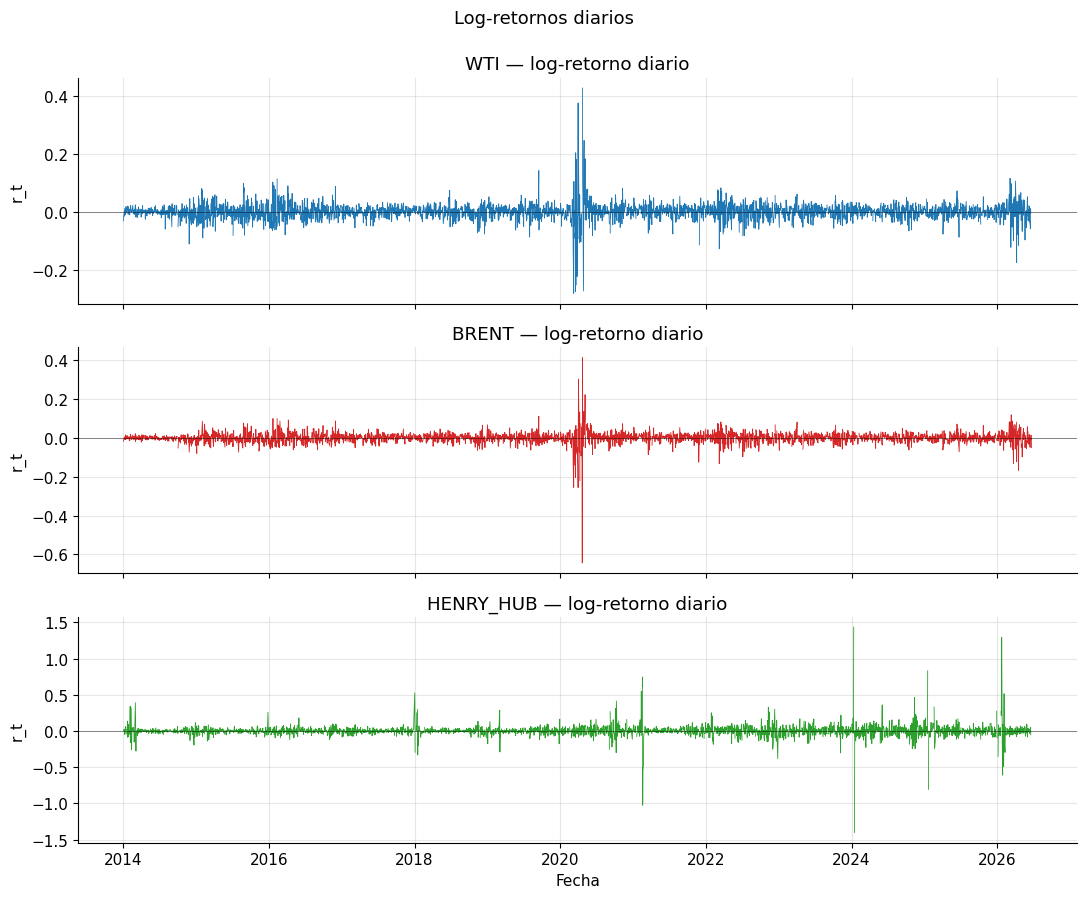

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, asset in zip(axes, ASSETS):
    ax.plot(ret.index, ret[asset], color=COLORS[asset], lw=0.6)
    ax.axhline(0, color="black", lw=0.6, alpha=0.5)
    ax.set_title(f"{asset} — log-retorno diario")
    ax.set_ylabel("r_t")
axes[-1].set_xlabel("Fecha")
fig.suptitle("Log-retornos diarios", y=0.995, fontsize=13)
fig.tight_layout()
plt.show()

## 4. El WTI negativo del 20 de abril de 2020

El cierre spot de WTI tocó un valor **negativo** (-36.98 USD) ese día: colapso de
demanda por COVID + falta de capacidad de almacenamiento en Cushing. Es un
**evento real**, no un error de datos.

Consecuencia técnica: `ln()` de un precio negativo es indefinido, así que el
log-retorno de esa transición queda `NaN` — pero el **precio se conserva**
(no se borra nada automáticamente, como manda el spec).

                     date asset  close  log_return
2020-04-20 00:00:00+00:00   WTI -36.98         NaN


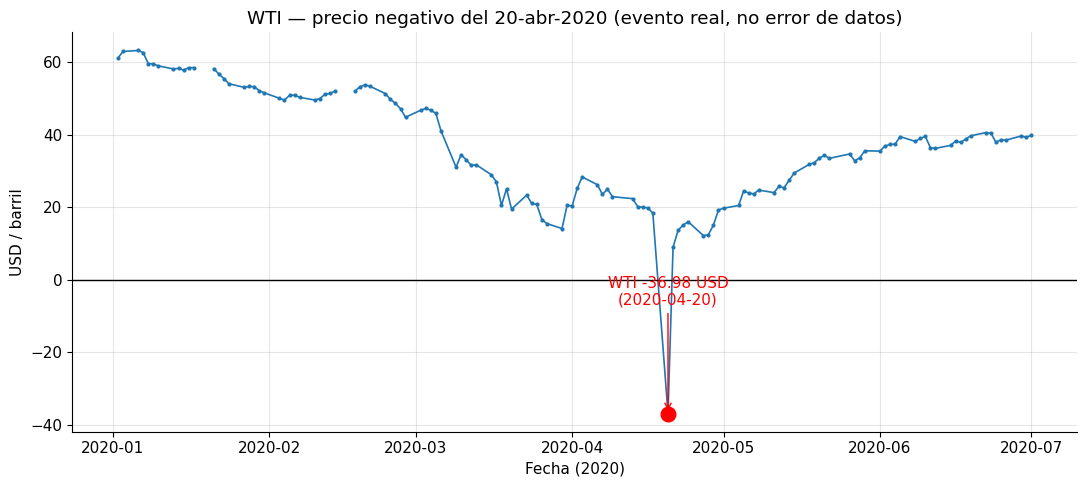

In [6]:
evento = df[(df["asset"] == "WTI") & (df["close"] <= 0)]
print(evento[["date", "asset", "close", "log_return"]].to_string(index=False))

# Zoom a la primera mitad de 2020 sobre WTI.
ini = pd.Timestamp("2020-01-01", tz="UTC")
fin = pd.Timestamp("2020-07-01", tz="UTC")
wti_2020 = close.loc[(close.index >= ini) & (close.index <= fin), "WTI"]

neg_date = evento["date"].iloc[0]
neg_val = float(evento["close"].iloc[0])

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(wti_2020.index, wti_2020.values, color=COLORS["WTI"], lw=1.2, marker=".", ms=4)
ax.axhline(0, color="black", lw=1.0)
ax.scatter([neg_date], [neg_val], color="red", s=110, zorder=5)
ax.annotate(f"WTI {neg_val:.2f} USD\n({neg_date.date()})",
            xy=(neg_date, neg_val), xytext=(neg_date, neg_val + 30),
            ha="center", color="red",
            arrowprops=dict(arrowstyle="->", color="red"))
ax.set_title("WTI — precio negativo del 20-abr-2020 (evento real, no error de datos)")
ax.set_ylabel("USD / barril")
ax.set_xlabel("Fecha (2020)")
fig.tight_layout()
plt.show()

## 5. Estadísticas descriptivas de los retornos

`curtosis_exceso` usa la convención de Fisher (pandas `.kurt()`): una Normal da
**0**. Valores claramente positivos indican **colas gordas** (leptocurtosis).
La asimetría negativa indica que los crashes son más bruscos que los rallies.

In [7]:
stats = pd.DataFrame({
    "media": ret.mean(),
    "desvio": ret.std(),
    "asimetria": ret.skew(),
    "curtosis_exceso": ret.kurt(),
    "n_obs": ret.count(),
}).loc[ASSETS]
stats.round(5)

,media,desvio,asimetria,curtosis_exceso,n_obs
asset,,,,,
WTI,0.00016,0.03027,0.87383,33.67499,3124
BRENT,-0.00011,0.03001,-2.54316,88.18525,3165
HENRY_HUB,0.00005,0.08369,1.11920,90.90521,3147


## 6. Distribución de retornos vs Normal (colas gordas)

Histograma empírico de cada activo con una Normal teórica (misma media y desvío)
superpuesta. Eje **y en escala logarítmica** para que las colas se vean: el
histograma empírico queda **por encima** de la Normal en los extremos —
hay muchos más eventos extremos de los que predeciría una Gaussiana.

Esto adelanta por qué más adelante usamos modelos que **no asumen normalidad**
(GARCH, distribuciones de colas pesadas, etc.).

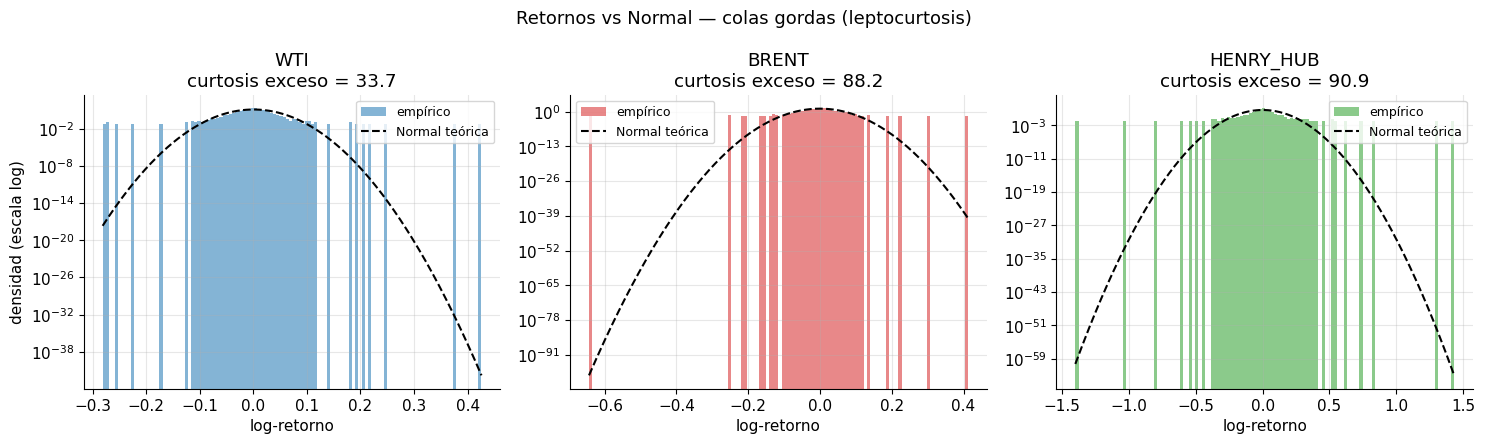

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, asset in zip(axes, ASSETS):
    r = ret[asset].dropna()
    mu, sigma = r.mean(), r.std()
    ax.hist(r, bins=120, density=True, color=COLORS[asset], alpha=0.55, label="empírico")
    x = np.linspace(r.min(), r.max(), 500)
    pdf = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
    ax.plot(x, pdf, "k--", lw=1.5, label="Normal teórica")
    ax.set_yscale("log")
    ax.set_title(f"{asset}\ncurtosis exceso = {r.kurt():.1f}")
    ax.set_xlabel("log-retorno")
    ax.legend(fontsize=9)
axes[0].set_ylabel("densidad (escala log)")
fig.suptitle("Retornos vs Normal — colas gordas (leptocurtosis)", fontsize=13)
fig.tight_layout()
plt.show()

## 7. Conteo de NaN por activo y por año

Los `NaN` de `close` son días en que **ese** mercado no operó (feriados propios
de cada mercado, que difieren entre WTI/Brent/Henry Hub). **No** son datos
perdidos: el test PiT ya verificó que no hay NaN silenciosos cruzando contra el
crudo. Este conteo es solo para dimensionar las diferencias de calendario.

In [9]:
na_por_activo = (df.groupby("asset", observed=True)["close"]
                   .apply(lambda s: int(s.isna().sum()))
                   .loc[ASSETS])
print("NaN de close por activo:")
print(na_por_activo.to_string())

NaN de close por activo:
asset
WTI          85
BRENT        46
HENRY_HUB    63


In [10]:
tmp = df.assign(year=df["date"].dt.year, na=df["close"].isna())
na_year = (tmp.pivot_table(index="year", columns="asset", values="na",
                           aggfunc="sum", observed=True)
              .reindex(columns=ASSETS).fillna(0).astype(int))
na_year

asset,WTI,BRENT,HENRY_HUB
year,,,
2014,5,3,1
2015,3,0,1
2016,7,5,0
2017,9,3,0
2018,6,1,7
2019,3,0,3
2020,6,3,7
2021,7,5,7
2022,9,8,8


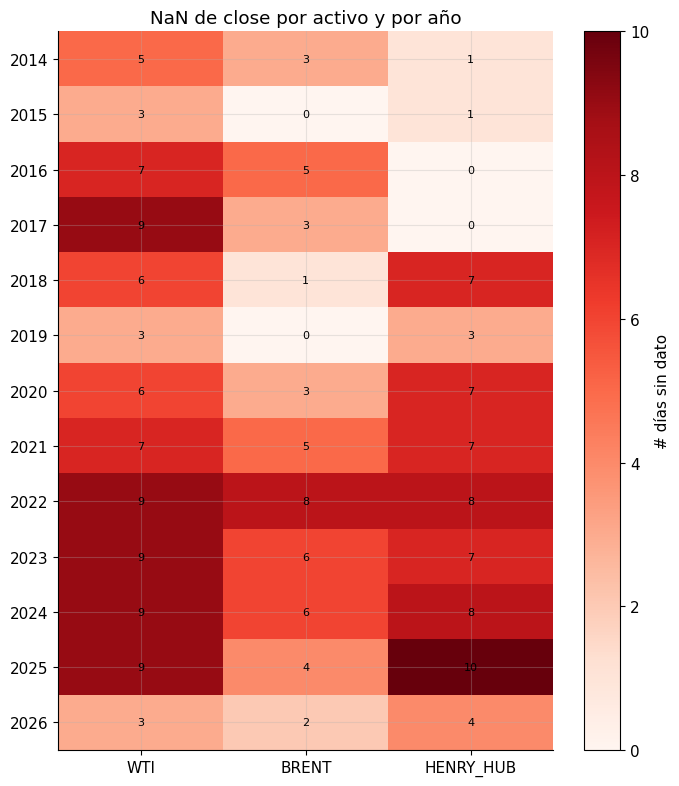

In [11]:
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(na_year.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(len(ASSETS)), ASSETS)
ax.set_yticks(range(len(na_year.index)), na_year.index)
for i in range(na_year.shape[0]):
    for j in range(na_year.shape[1]):
        ax.text(j, i, na_year.values[i, j], ha="center", va="center", fontsize=8)
ax.set_title("NaN de close por activo y por año")
fig.colorbar(im, ax=ax, label="# días sin dato")
fig.tight_layout()
plt.show()

## Conclusiones

- Las tres series de precios son **coherentes** y cubren 2014 → hoy.
- Los log-retornos muestran **clusters de volatilidad** y **colas gordas**
  marcadas (curtosis en exceso >> 0): la Normal **subestima** el riesgo de cola.
- El WTI negativo de abril 2020 es un **evento real**, manejado sin romper el
  pipeline (precio conservado, retorno `NaN`).
- Los `NaN` están **explicados** (diferencias de calendario), no son datos perdidos.

→ Justifica usar, en los módulos siguientes, modelos de volatilidad que no
asuman normalidad.